# Kondycja finansowa a bankructwo w ciągu roku
### Analiza rentowności, historii wyników, płynności oraz zadłużenia i kosztów

**Celem analizy jest ustalenie, jakie różnice w kondycji finansowej towarzyszą bankructwu w kolejnym roku i czy sygnały z różnych obszarów finansów współwystępują.**

Badanie obejmuje 5846 rekordów sprawozdań i 13 wskaźników: **X1, X2, X3, X5, X6, X24, X29, X34, X35, X46, X56, X58 i X62**. `class = 1` oznacza bankructwo w rocznym horyzoncie po obserwacji danych; `class = 0` — brak bankructwa w tym okresie. Bez identyfikatorów nie potwierdzamy, że każdy rekord odpowiada innej firmie.

Analiza jest uporządkowana według obszarów finansowych. W każdym określono cel, przeprowadzono porównanie obu grup i badanie uzupełniające, a następnie sformułowano interpretację. Osobno oceniono korelacje wszystkich wskaźników oraz współwystępowanie sygnałów z rentowności i finansowania krótkoterminowego.

Źródło: [UCI — Polish Companies Bankruptcy](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data), część `5year.arff` z rocznym horyzontem prognozy. Dane odczytano z `dane_do_analizy.xlsx`.

## 1. Co oznaczają analizowane wskaźniki?

| Wskaźnik | Definicja | Znaczenie finansowe |
|:--|:--|:--|
| **X1 — rentowność aktywów netto** | Zysk netto / aktywa ogółem | Ocena zysku netto względem majątku; wynik ujemny oznacza stratę. |
| **X2 — zadłużenie ogólne** | Zobowiązania ogółem / aktywa ogółem | Skala zobowiązań wobec majątku. Wynik powyżej 1 oznacza zobowiązania większe od aktywów i jest ekonomicznie możliwy. |
| **X3 — kapitał obrotowy do aktywów** | (Aktywa obrotowe − zobowiązania krótkoterminowe) / aktywa ogółem | Ujemny wynik oznacza niedobór aktywów obrotowych względem bieżącego długu. |
| **X5 — bufor płynności wobec kosztów** | 365 × (gotówka + krótkoterminowe papiery wartościowe + należności − zobowiązania krótkoterminowe) / (koszty operacyjne − amortyzacja) | Bufor płynnych składników wobec kosztów ze wzoru UCI. Znak zależy też od mianownika; to nie dosłowny czas do utraty gotówki. |
| **X6 — wynik zatrzymany do aktywów** | Wynik zatrzymany / aktywa ogółem | Akumulacja wyników pozostawionych w firmie wobec majątku. Nie jest bieżącym stanem gotówki. |
| **X24 — wynik brutto z trzech lat do aktywów** | Zysk brutto z trzech lat / aktywa ogółem, według UCI | Dłuższa perspektywa wyników; nie traktujemy jej jako średniorocznej stopy zysku. |
| **X29 — wielkość przedsiębiorstwa** | Logarytm aktywów ogółem | Większy wynik oznacza większe aktywa. Bez podstawy logarytmu i jednostki aktywów nie przeliczamy na kwoty. |
| **X34 — koszty operacyjne do zobowiązań** | Koszty operacyjne / zobowiązania ogółem | Wzrost może oznaczać większe koszty albo mniejsze zobowiązania; nie ma jednej automatycznie korzystnej interpretacji. |
| **X35 — rentowność majątku na poziomie sprzedaży** | Wynik na sprzedaży / aktywa ogółem | Wynik podstawowej działalności sprzedażowej wobec majątku; inny poziom wyniku niż zysk netto. |
| **X46 — płynność szybka** | (Aktywa obrotowe − zapasy) / zobowiązania krótkoterminowe | Pokrycie bieżącego długu aktywami obrotowymi bez zapasów. Wynik 1 nie gwarantuje zdolności płatniczej. |
| **X56 — marża po wskazanych kosztach sprzedaży** | (Sprzedaż − koszt sprzedanych produktów) / sprzedaż | Część sprzedaży pozostająca po wskazanych kosztach. Nie jest to marża netto. |
| **X58 — kosztochłonność sprzedaży** | Koszty ogółem / sprzedaż ogółem | Wynik powyżej 1 oznacza przewagę kosztów nad sprzedażą. |
| **X62 — zobowiązania krótkoterminowe wobec sprzedaży** | 365 × zobowiązania krótkoterminowe / sprzedaż | Skala bieżącego długu wobec dziennej sprzedaży. Nie jest dokładnym terminem płatności. |

X1, X2, X3, X6, X24 i X35 prezentujemy w **procentach aktywów**, X56 i X58 w **procentach sprzedaży**. X34 i X46 są ilorazami. 

## 2. Organizacja badania i cele poszczególnych obszarów

Wskaźniki pogrupowano według ich znaczenia ekonomicznego. Podział porządkuje kolejne pytania badawcze: od zdolności generowania wyniku, przez historię jego akumulacji, do krótkoterminowego finansowania i skali obciążeń. Nie jest to klasyfikacja oparta wyłącznie na korelacjach. Niektóre miary łączą kilka obszarów, dlatego ich współzależności oceniono także w dalszej części.

| Obszar | Wskaźniki | Cel badania |
|:--|:--|:--|
| **Rentowność** | X1, X35, X56 | Ustalenie, czy słabszy wynik firm z bankructwem jest widoczny na poziomie netto i działalności sprzedażowej oraz jak często wyniki przyjmują wartości ujemne. |
| **Historia wyników i skala działalności** | X6, X24, X29 | Ocena akumulacji wyników i rentowności z szerszego okresu. Wielkość majątku stanowi kontekst pozwalający sprawdzić, czy różnice historycznej rentowności występują również w podobnych klasach rozmiaru. |
| **Płynność** | X3, X5, X46 | Ocena bufora aktywów obrotowych i płynnych składników wobec bieżących zobowiązań oraz związku stopnia pokrycia tych zobowiązań z częstością bankructw. |
| **Zadłużenie i koszty** | X2, X34, X58, X62 | Ocena obciążenia majątku i sprzedaży oraz sprawdzenie, czy przewaga zobowiązań nad aktywami współwystępująca z przewagą kosztów nad sprzedażą łączy się z większą częstością bankructw. |

### Metodyka

Każdy z 13 wskaźników porównano między grupami pod względem liczebności, średniej, mediany, kwartylów i rozkładu. Uzupełniająco wykorzystano efekt rangowy oraz korelacje Spearmana liczone dla całej próby i osobno w obu grupach. Wyników brakujących nie imputowano. Statystyki jednowymiarowe obliczano na dostępnych wartościach, a zależności na obserwacjach kompletnych dla analizowanej pary.

Progi ekonomiczne, takie jak zero wyniku, zobowiązania równe aktywom i koszty równe sprzedaży, ustalono na podstawie definicji wskaźników. Podział rozmiaru przedsiębiorstw wyznaczają kwartyle X29 wspólne dla obu grup. Analizy są opisowe; nie służą do identyfikacji przyczyn ani optymalizacji progów modelu.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from matplotlib.ticker import PercentFormatter
from IPython.display import display
DATA = Path('dane_do_analizy.xlsx')
if not DATA.exists():
    DATA = Path('C:/Users/jakub/Desktop/Analiza_bankructwa_5year/dane_do_analizy.xlsx')
FEATURES = ['X1', 'X2', 'X3', 'X5', 'X6', 'X24', 'X29', 'X34', 'X35', 'X46', 'X56', 'X58', 'X62']
source_hash = hashlib.sha256(DATA.read_bytes()).hexdigest()
df = pd.read_excel(DATA, sheet_name='Dane_czyste_z_brakami', usecols=FEATURES + ['class'])[FEATURES + ['class']]
assert set(df['class'].unique()) == {0, 1}
assert not np.isinf(df[FEATURES]).any().any()
NAMES = {'X1': 'Rentowność netto', 'X2': 'Zadłużenie ogólne', 'X3': 'Kapitał obrotowy', 'X5': 'Bufor płynności', 'X6': 'Wynik zatrzymany', 'X24': 'Wynik z trzech lat', 'X29': 'Wielkość firmy', 'X34': 'Koszty / zobowiązania', 'X35': 'Rentowność na sprzedaży', 'X46': 'Płynność szybka', 'X56': 'Marża sprzedaży', 'X58': 'Koszty / sprzedaż', 'X62': 'Dług / sprzedaż'}
UNITS = {'X1': ('% aktywów', 100), 'X2': ('% aktywów', 100), 'X3': ('% aktywów', 100), 'X5': ('wg wzoru UCI', 1), 'X6': ('% aktywów', 100), 'X24': ('% aktywów', 100), 'X29': ('log aktywów', 1), 'X34': ('razy', 1), 'X35': ('% aktywów', 100), 'X46': ('razy', 1), 'X56': ('% sprzedaży', 100), 'X58': ('% sprzedaży', 100), 'X62': ('dni wg wzoru', 1)}
BLUE, RED, INK = ('#28799A', '#D76A50', '#17324D')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'figure.facecolor': 'white', 'axes.facecolor': '#FAFCFD', 'axes.labelcolor': INK, 'axes.titleweight': 'bold', 'axes.titlesize': 13, 'axes.spines.top': False, 'axes.spines.right': False, 'grid.color': '#DDE5EB', 'savefig.dpi': 160})

def pl(v, digits=2):
    return f'{v:,.{digits}f}'.replace(',', ' ').replace('.', ',')

def table(frame):
    display(frame.style.hide(axis='index').set_table_styles([{'selector': 'th', 'props': [('background', '#17324D'), ('color', 'white'), ('padding', '9px 11px'), ('text-align', 'left')]}, {'selector': 'td', 'props': [('padding', '8px 11px'), ('border-bottom', '1px solid #e3eaf0'), ('text-align', 'left')]}, {'selector': 'table', 'props': [('border-collapse', 'collapse'), ('font-family', 'Arial, sans-serif'), ('font-size', '13px')]}]))
COUNTS = df['class'].value_counts().sort_index()
GROUPS = {'Rentowność': ['X1', 'X35', 'X56'], 'Historia i skala': ['X6', 'X24', 'X29'], 'Płynność': ['X3', 'X5', 'X46'], 'Zadłużenie i koszty': ['X2', 'X34', 'X58', 'X62']}
assert set((c for cols in GROUPS.values() for c in cols)) == set(FEATURES)
assert sum(map(len, GROUPS.values())) == len(FEATURES)
STATS = {}
EFFECT = {}
for c in FEATURES:
    STATS[c] = {g: df.loc[df['class'] == g, c].dropna() for g in [0, 1]}
    a, b = (STATS[c][0], STATS[c][1])
    EFFECT[c] = 2 * mannwhitneyu(b, a, alternative='two-sided').statistic / (len(a) * len(b)) - 1

def group_table(cols):
    rows = []
    for c in cols:
        unit, f = UNITS[c]
        a = STATS[c][0] * f
        b = STATS[c][1] * f

        def central(s):
            return pl(s.median()) + ' [' + pl(s.quantile(0.25)) + '; ' + pl(s.quantile(0.75)) + ']'
        rows.append({'Wskaźnik / jednostka': c + ' / ' + unit, 'n: 0 / 1': f'{len(a)} / {len(b)}', 'Średnia 0': pl(a.mean()), 'Mediana 0 [Q1; Q3]': central(a), 'Średnia 1': pl(b.mean()), 'Mediana 1 [Q1; Q3]': central(b), 'Efekt rangowy': pl(EFFECT[c], 3)})
    table(pd.DataFrame(rows))

def box_panel(ax, c):
    unit, f = UNITS[c]
    vals = [STATS[c][g].to_numpy() * f for g in [0, 1]]
    bp = ax.boxplot(vals, patch_artist=True, showfliers=False, widths=0.48, medianprops={'color': INK, 'linewidth': 2}, whiskerprops={'color': '#778996'}, capprops={'color': '#778996'})
    for box, color in zip(bp['boxes'], [BLUE, RED]):
        box.set(facecolor=color, alpha=0.65, edgecolor=color)
    ax.set_xticks([1, 2], ['Bez bankructwa', 'Bankructwo' + chr(10) + 'w ciągu roku'])
    ax.set_title(c + ' — ' + NAMES[c], fontsize=12, pad=12)
    ax.set_ylabel(unit)
    ref = {'X1': 0, 'X35': 0, 'X56': 0, 'X24': 0, 'X3': 0, 'X5': 0, 'X46': 1, 'X2': 100, 'X58': 100}
    if c in ref:
        ax.axhline(ref[c], color=INK, linestyle='--', linewidth=1, alpha=0.7)
    for pos, v in enumerate(vals, 1):
        ax.annotate(pl(np.median(v)), (pos, np.median(v)), xytext=(0, 7), textcoords='offset points', fontsize=9, color=INK, va='bottom', ha='center', bbox={'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'none', 'pad': 2})
    ax.grid(axis='y', alpha=0.6)
    ax.set_axisbelow(True)
table(pd.DataFrame({'Grupa': ['Bez bankructwa', 'Bankructwo w ciągu roku'], 'Rekordy': [int(COUNTS[0]), int(COUNTS[1])], 'Udział': [pl(COUNTS[0] / len(df) * 100) + '%', pl(COUNTS[1] / len(df) * 100) + '%']}))




liczba_rekordow = len(df)
liczba_wskaznikow = len(FEATURES)
liczebnosci_klas = df['class'].value_counts().sort_index()
udzial_bankructw_proc = 100 * liczebnosci_klas.loc[1] / liczba_rekordow
# print('Rekordy:', liczba_rekordow, '| wskaźniki:', liczba_wskaznikow)
# print(liczebnosci_klas.rename('n').to_string())
# print('Udział bankructw =', int(liczebnosci_klas.loc[1]), '/', liczba_rekordow, '* 100 =', pl(udzial_bankructw_proc), '%')


kontrola_wiersze = []
for wskaznik in FEATURES:
    jednostka, przelicznik = UNITS[wskaznik]
    for klasa in [0, 1]:
        wszystkie = df.loc[df['class'] == klasa, wskaznik]
        dostepne = wszystkie.dropna()
        n_dostepnych = int(dostepne.count())
        n_ujemnych = int((dostepne < 0).sum())
        n_zero = int((dostepne == 0).sum())
        n_dodatnich = int((dostepne > 0).sum())
        kontrola_wiersze.append({
            'Wskaznik': wskaznik, 'class': klasa,
            'n_grupy': len(wszystkie), 'n_dostepnych': n_dostepnych,
            'n_brakow': int(wszystkie.isna().sum()),
            'n_ujemnych': n_ujemnych, 'n_zero': n_zero, 'n_dodatnich': n_dodatnich,
            'ujemne_proc': 100 * n_ujemnych / n_dostepnych,
            'zero_proc': 100 * n_zero / n_dostepnych,
            'dodatnie_proc': 100 * n_dodatnich / n_dostepnych,
            'jednostka': jednostka,
            'srednia': dostepne.mean() * przelicznik,
            'mediana': dostepne.median() * przelicznik,
            'Q1': dostepne.quantile(.25) * przelicznik,
            'Q3': dostepne.quantile(.75) * przelicznik,
            'efekt_rangowy': EFFECT[wskaznik]
        })
KONTROLA_STATYSTYK = pd.DataFrame(kontrola_wiersze).set_index(['Wskaznik', 'class'])
# print(KONTROLA_STATYSTYK.to_string())

Grupa,Rekordy,Udział
Bez bankructwa,5438,"93,02%"
Bankructwo w ciągu roku,408,"6,98%"


**Wniosek.** Bankructwa stanowią **6,98%** próby. Wykresy porównują rozkłady lub odsetki wewnątrz grup, a nie surowe liczby, które byłyby zdominowane przez większą grupę bez bankructwa. Częstości odnoszą się do tego zbioru, nie do wszystkich polskich przedsiębiorstw.

## 3. Dostępność danych

Liczebności dostępnych wyników określają zakres porównań. Brak w pojedynczej kolumnie nie powoduje wyłączenia sprawozdania z pozostałych obliczeń.

In [2]:
rows = []
for c in FEATURES:
    n0 = int(df.loc[df['class'] == 0, c].isna().sum())
    n1 = int(df.loc[df['class'] == 1, c].isna().sum())
    rows.append({'Wskaźnik': c, 'Braki: bez bankructwa': f'{n0} ({pl(n0 / COUNTS[0] * 100)}%)', 'Braki: bankructwo': f'{n1} ({pl(n1 / COUNTS[1] * 100)}%)', 'Dostępne ogółem': int(df[c].notna().sum())})
table(pd.DataFrame(rows))
c = df[FEATURES].isna().mean().idxmax()




braki_wiersze = []
for wskaznik in FEATURES:
    for klasa in [0, 1]:
        wyniki = df.loc[df['class'] == klasa, wskaznik]
        n_brakow = int(wyniki.isna().sum())
        braki_wiersze.append({'Wskaznik': wskaznik, 'class': klasa,
            'braki': n_brakow, 'n_grupy': len(wyniki),
            'braki_proc': 100 * n_brakow / len(wyniki)})
KONTROLA_BRAKOW = pd.DataFrame(braki_wiersze).set_index(['Wskaznik', 'class'])
braki_ogolem = df[FEATURES].isna().sum()
udzial_brakow_ogolem = 100 * braki_ogolem / len(df)
najwiecej_brakow = udzial_brakow_ogolem.idxmax()
# print(KONTROLA_BRAKOW.to_string())
# print('Największy udział braków:', najwiecej_brakow, '|', int(braki_ogolem[najwiecej_brakow]), '/', len(df), '* 100 =', pl(udzial_brakow_ogolem[najwiecej_brakow]), '%')
# print('X34 — liczebności braków i odsetki:', KONTROLA_BRAKOW.loc['X34'].to_string())

Wskaźnik,Braki: bez bankructwa,Braki: bankructwo,Dostępne ogółem
X1,"0 (0,00%)","1 (0,25%)",5845
X2,"1 (0,02%)","1 (0,25%)",5844
X3,"0 (0,00%)","1 (0,25%)",5845
X5,"11 (0,20%)","0 (0,00%)",5835
X6,"0 (0,00%)","1 (0,25%)",5845
X24,"132 (2,43%)","1 (0,25%)",5713
X29,"0 (0,00%)","1 (0,25%)",5845
X34,"11 (0,20%)","3 (0,74%)",5832
X35,"0 (0,00%)","1 (0,25%)",5845
X46,"18 (0,33%)","6 (1,47%)",5822


**Wniosek.** Największy udział braków w analizowanym zestawie ma **X24: 2,28%**. Porównania opierają się zatem na dużej części próby. X34 ma 11 braków bez bankructwa i 3 przy bankructwie; taka kompletność pozwala opisać go bez zastępowania nieznanych wyników wartościami typowymi. Braki nie są jednak automatycznie losowe, więc przy interpretacji zawsze zachowujemy liczebności.

## 4. Rentowność: X1, X35 i X56

### Cel i zakres badania

Sprawdzono, czy różnice między grupami obejmują zarówno końcowy wynik netto, jak i wynik działalności sprzedażowej. X1 i X35 odnoszą różne poziomy wyniku do aktywów, natomiast X56 opisuje nadwyżkę sprzedaży nad wskazanymi kosztami w relacji do sprzedaży. Zestawienie pozwala ocenić, czy trudności ujawniają się na kilku poziomach wyniku, a nie tylko w jego jednej pozycji.

Najpierw porównano poziom i zróżnicowanie wskaźników. Następnie określono udział wartości ujemnych, aby ustalić, czy różnica median odpowiada częstszemu występowaniu strat, czy wynika przede wszystkim z rozmiaru wyników.

W tabelach **0 oznacza brak bankructwa, a 1 bankructwo**. Zapis w nawiasach obejmuje Q1–Q3.

Wskaźnik / jednostka,n: 0 / 1,Średnia 0,Mediana 0 [Q1; Q3],Średnia 1,Mediana 1 [Q1; Q3],Efekt rangowy
X1 / % aktywów,5438 / 407,"7,66","5,18 [0,73; 12,08]","-136,07","-6,70 [-23,29; 2,36]","-0,534"
X35 / % aktywów,5438 / 407,"8,28","6,61 [1,22; 14,16]","-123,09","-6,90 [-23,90; 3,83]","-0,560"
X56 / % sprzedaży,5438 / 408,"7,33","5,66 [1,55; 12,87]","-16,97","-1,45 [-15,48; 4,74]","-0,453"


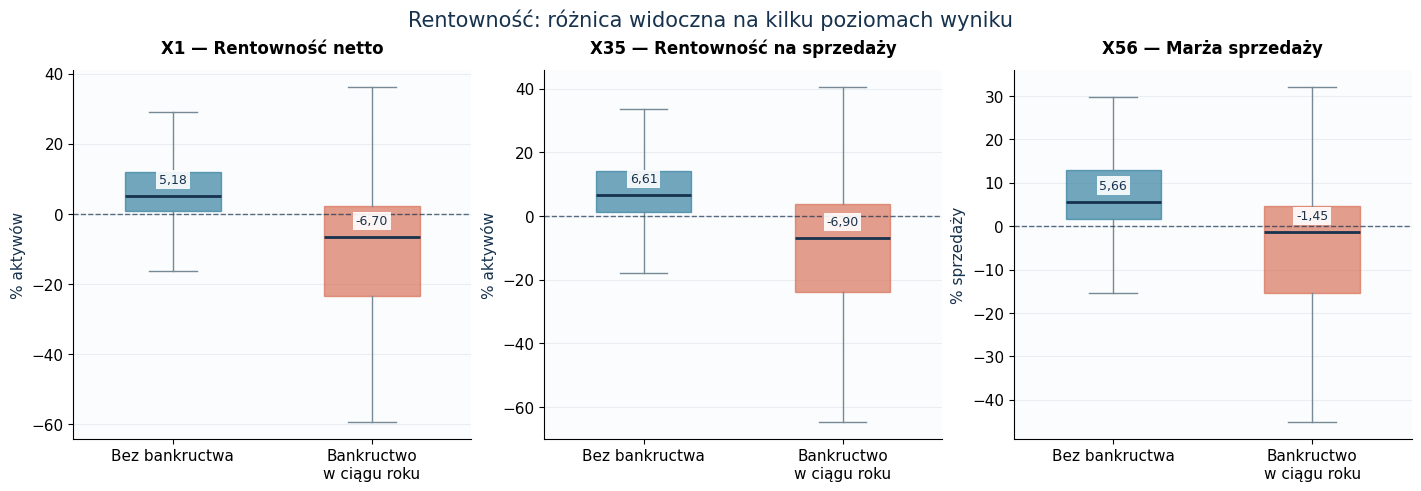

In [3]:
group_table(GROUPS['Rentowność'])
fig, axes = plt.subplots(1, 3, figsize=(14.1, 4.8), layout='constrained')
for ax, c in zip(axes, GROUPS['Rentowność']):
    box_panel(ax, c)
fig.suptitle('Rentowność: różnica widoczna na kilku poziomach wyniku', fontsize=15, color=INK)
plt.show()
a, b = (STATS['X1'][0], STATS['X1'][1])




kontrola_rentownosci = KONTROLA_STATYSTYK.loc[GROUPS['Rentowność'], ['n_dostepnych', 'jednostka', 'srednia', 'mediana', 'Q1', 'Q3', 'efekt_rangowy']]
# print(kontrola_rentownosci.to_string())


straty_X1 = df.groupby('class')['X1'].agg(
    n_dostepnych='count',
    n_ujemnych=lambda wyniki: int((wyniki < 0).sum()),
    n_nieujemnych=lambda wyniki: int((wyniki >= 0).sum())
)
straty_X1['odsetek_strat_proc'] = 100 * straty_X1['n_ujemnych'] / straty_X1['n_dostepnych']
# print(straty_X1.to_string())
# print('Bankructwo: ', int(straty_X1.loc[1, 'n_ujemnych']), '/', int(straty_X1.loc[1, 'n_dostepnych']), '* 100 =', pl(straty_X1.loc[1, 'odsetek_strat_proc'], 1), '%')
# print('Bez bankructwa: ', int(straty_X1.loc[0, 'n_ujemnych']), '/', int(straty_X1.loc[0, 'n_dostepnych']), '* 100 =', pl(straty_X1.loc[0, 'odsetek_strat_proc'], 1), '%')

**X1 — wynik netto.** Mediana spada z **5,18%** do **-6,70% aktywów**. Taki wynik jest spójny z mniejszą zdolnością odbudowy kapitału z zysku, ale strata nie jest równoznaczna z brakiem gotówki ani nie przesądza o bankructwie.

**X35 — działalność sprzedażowa.** Mediana wynosi **6,61%** i **-6,90% aktywów**. Różnica już na tym poziomie pokazuje, że obserwowane trudności nie ograniczają się do końcowego wyniku netto. Nie ustalamy jednak bez rachunku wyników, które pozycje kosztowe odpowiadają za różnicę.

**X56 — marża po wskazanych kosztach.** Mediany **5,66%** i **-1,45% sprzedaży** wskazują na mniejszą nadwyżkę sprzedaży nad kosztami z tego wzoru w grupie bankructw. To odmienny mianownik niż w X1 i X35, więc wysokości tych trzech procentów nie porównujemy jak tej samej marży. Nakładanie się rozkładów oznacza, że nie ma jednego progu oddzielającego wszystkie firmy.

### Częstość ujemnych wyników

Ujemne X1 i X35 oznaczają stratę odpowiednio na poziomie netto i wyniku na sprzedaży. Ujemne X56 oznacza, że koszt sprzedanych produktów przewyższa sprzedaż w zakresie pozycji użytych w tym wzorze. Zestawienie udziałów pozwala rozróżnić częstotliwość problemu od skali pojedynczej straty. Odsetki obliczono na dostępnych wartościach każdego wskaźnika.

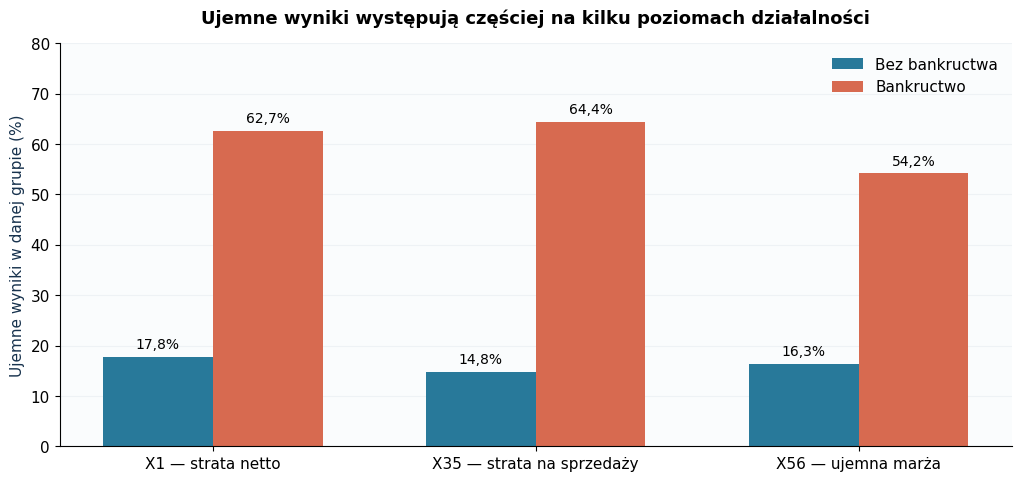

In [4]:
profit_cols=['X1','X35','X56']
negative_share={g:np.array([(STATS[c][g]<0).mean()*100 for c in profit_cols]) for g in [0,1]}
fig,ax=plt.subplots(figsize=(10.1,4.7),layout='constrained')
xs=np.arange(3);width=.34
for g,color,label,offset in [(0,BLUE,'Bez bankructwa',-width/2),(1,RED,'Bankructwo',width/2)]:
    bars=ax.bar(xs+offset,negative_share[g],width=width,color=color,label=label)
    ax.bar_label(bars,labels=[pl(v,1)+'%' for v in negative_share[g]],padding=4,fontsize=10)
ax.set_xticks(xs,['X1 — strata netto','X35 — strata na sprzedaży','X56 — ujemna marża'])
ax.set_ylabel('Ujemne wyniki w danej grupie (%)');ax.set_ylim(0,80)
ax.set_title('Ujemne wyniki występują częściej na kilku poziomach działalności',pad=14)
ax.legend(frameon=False);ax.grid(axis='y',alpha=.4);ax.set_axisbelow(True)
plt.show()




ujemne_wyniki = []
for wskaznik in profit_cols:
    for klasa in [0, 1]:
        dostepne = df.loc[df['class'] == klasa, wskaznik].dropna()
        liczba_ujemnych = int((dostepne < 0).sum())
        ujemne_wyniki.append({'Wskaznik': wskaznik, 'class': klasa,
            'n_ujemnych': liczba_ujemnych, 'n_dostepnych': len(dostepne),
            'odsetek_proc': 100 * liczba_ujemnych / len(dostepne)})
KONTROLA_UJEMNYCH = pd.DataFrame(ujemne_wyniki)
# print(KONTROLA_UJEMNYCH.to_string(index=False))

**Wnioski.** Stratę netto wykazuje **62,7%** dostępnych rekordów bankructw wobec **17,8%** bez bankructwa. Ujemny wynik na sprzedaży występuje odpowiednio w **64,4% i 14,8%**, a ujemne X56 w **54,2% i 16,3%**. Różnica dotyczy zatem nie tylko głębokości strat, lecz także ich częstszego występowania na różnych poziomach działalności.

Wysoki udział ujemnego X35 jest spójny z problemami w generowaniu wyniku na sprzedaży, a nie wyłącznie z obciążeniami pomiędzy tym wynikiem a wynikiem netto. Nie oznacza to, że te same firmy mają ujemne wszystkie trzy wskaźniki — odsetki opisują każdą cechę osobno. Ujemny wynik może ograniczać odbudowę kapitału z działalności, ale nie określa bezpośrednio dostępnej gotówki.

## 5. Historia wyników i skala działalności: X6, X24 i X29

### Cel i zakres badania

Sprawdzono, czy bieżącym różnicom rentowności towarzyszy słabsza akumulacja wyników i niższy wynik w szerszej perspektywie. X6 opisuje wynik zatrzymany względem majątku, a X24 wynik brutto z trzech lat względem aktywów. X29 określa rozmiar majątku i pełni w tej grupie rolę kontekstu, a nie kolejnej miary rentowności.

Po porównaniu rozkładów zbadano X24 w czterech klasach wielkości. Pozwala to ocenić, czy różnica historycznej rentowności jest widoczna również w obrębie podobnego przedziału rozmiaru, czy pojawia się jedynie w zbiorczym porównaniu grup o innej strukturze wielkości.

Wskaźnik / jednostka,n: 0 / 1,Średnia 0,Mediana 0 [Q1; Q3],Średnia 1,Mediana 1 [Q1; Q3],Efekt rangowy
X6 / % aktywów,5438 / 407,"15,33","0,00 [0,00; 12,40]","-172,86","-1,18 [-29,12; 0,00]","-0,445"
X24 / % aktywów,5306 / 407,"24,63","17,66 [3,83; 36,77]","-127,25","-4,69 [-29,14; 13,29]","-0,418"
X29 / log aktywów,5438 / 407,"4,18","4,19 [3,68; 4,69]","3,67","3,74 [3,03; 4,26]","-0,328"


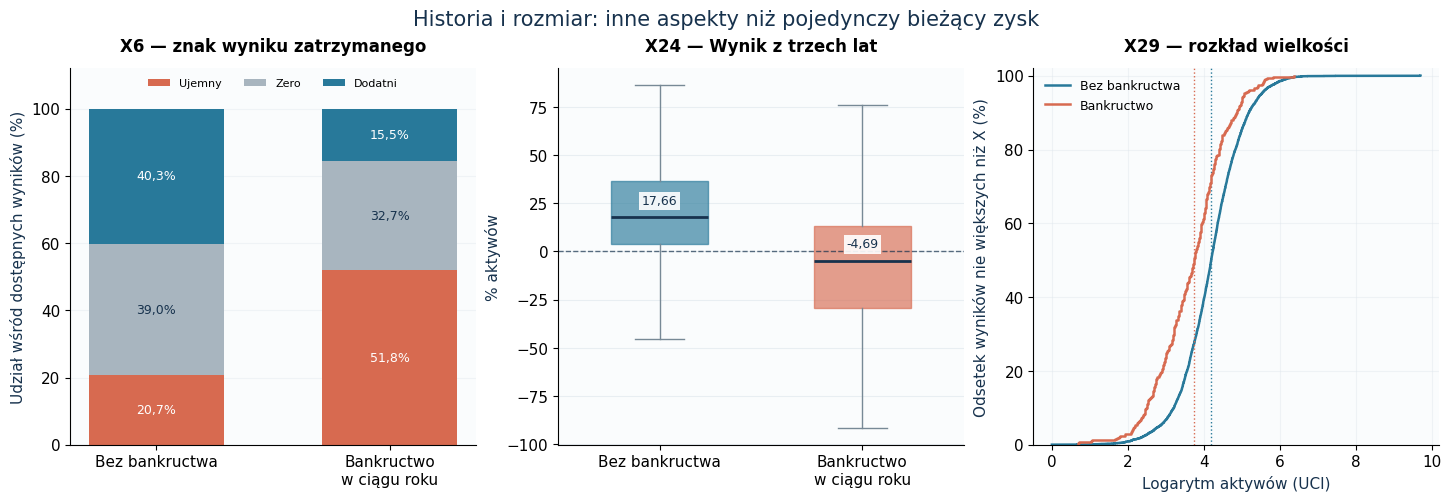

In [5]:
group_table(GROUPS['Historia i skala'])
fig, axes = plt.subplots(1, 3, figsize=(14.4, 4.9), layout='constrained')
ax = axes[0]
starts = np.zeros(2)
for title, color, predicate in [('Ujemny', RED, lambda s: s < 0), ('Zero', '#A8B5BF', lambda s: s == 0), ('Dodatni', BLUE, lambda s: s > 0)]:
    shares = np.array([predicate(STATS['X6'][g]).mean() * 100 for g in [0, 1]])
    ax.bar([0, 1], shares, bottom=starts, color=color, label=title, width=0.58)
    for j, v in enumerate(shares):
        if v >= 6:
            ax.text(j, starts[j] + v / 2, pl(v, 1) + '%', ha='center', va='center', fontsize=9, color='white' if color != '#A8B5BF' else INK)
    starts += shares
ax.set_xticks([0, 1], ['Bez bankructwa', 'Bankructwo' + chr(10) + 'w ciągu roku'])
ax.set_ylim(0, 112)
ax.set_ylabel('Udział wśród dostępnych wyników (%)')
ax.set_title('X6 — znak wyniku zatrzymanego', fontsize=12, pad=12)
ax.legend(frameon=False, loc='upper center', ncol=3, fontsize=8)
ax.grid(axis='y', alpha=0.35)
ax.set_axisbelow(True)
box_panel(axes[1], 'X24')
ax = axes[2]
for g, color, label in [(0, BLUE, 'Bez bankructwa'), (1, RED, 'Bankructwo')]:
    vals = np.sort(STATS['X29'][g].to_numpy())
    ax.step(vals, np.arange(1, len(vals) + 1) / len(vals) * 100, where='post', color=color, label=label, linewidth=1.8)
    ax.axvline(np.median(vals), color=color, linestyle=':', linewidth=1)
ax.set_title('X29 — rozkład wielkości', fontsize=12, pad=12)
ax.set_xlabel('Logarytm aktywów (UCI)')
ax.set_ylabel('Odsetek wyników nie większych niż X (%)')
ax.set_ylim(0, 102)
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.4)
fig.suptitle('Historia i rozmiar: inne aspekty niż pojedynczy bieżący zysk', fontsize=15, color=INK)
plt.show()




kontrola_X6 = KONTROLA_STATYSTYK.loc['X6', ['n_dostepnych', 'n_ujemnych', 'n_zero', 'n_dodatnich', 'ujemne_proc', 'zero_proc', 'dodatnie_proc', 'mediana']]
kontrola_historii = KONTROLA_STATYSTYK.loc[['X24', 'X29'], ['n_dostepnych', 'jednostka', 'srednia', 'mediana', 'Q1', 'Q3']]
# print('X6 — liczebności i udziały znaków:', kontrola_X6.to_string())
# print('X24 i X29 — wyniki w jednostkach tabeli:', kontrola_historii.to_string())

**X6 — wynik zatrzymany.** Ujemny zapis występuje u **51,8%** dostępnych rekordów bankructw i **20,7%** bez bankructwa. To silniejszy obraz niż sama mediana 0 w drugiej grupie: zero obejmuje dużą część rozkładu, ale nie opisuje całej historii. Wynik zatrzymany jest pozycją kapitałową, nie saldem gotówki. Nie wiemy też, czy zapisane zero oznacza dokładne zero czy zaokrąglenie.

**X24 — perspektywa trzech lat.** Mediana wynosi **17,66%** i **-4,69% aktywów**. Ujemny typowy wynik w grupie bankructw jest spójny ze słabszą sytuacją w szerszej perspektywie niż jeden okres. Dane nie pozwalają jednak odtworzyć kolejności wyników w trzech latach, więc nie stwierdzamy, że strata rosła co roku.

**X29 — wielkość.** Mediany **4,193** i **3,741** oraz przesunięcie dystrybuanty wskazują na mniejsze aktywa w grupie bankructw w tej próbie. Nie przeliczamy różnicy na złote ani procent różnicy majątku bez podstawy logarytmu i jednostki. Różne branże i wiek firm mogą współtworzyć zależność; nie dowodzi ona ochronnego działania samego rozmiaru.

### Rentowność historyczna w klasach wielkości

Klasy rozmiaru wyznaczono kwartylami X29 w całej próbie z dostępną wartością tej cechy. Granice są wspólne dla obu grup. W każdym przedziale porównano medianę X24 i liczbę dostępnych obserwacji. Jest to stratyfikacja opisowa, a nie kontrola wszystkich czynników wpływających na wyniki firm.

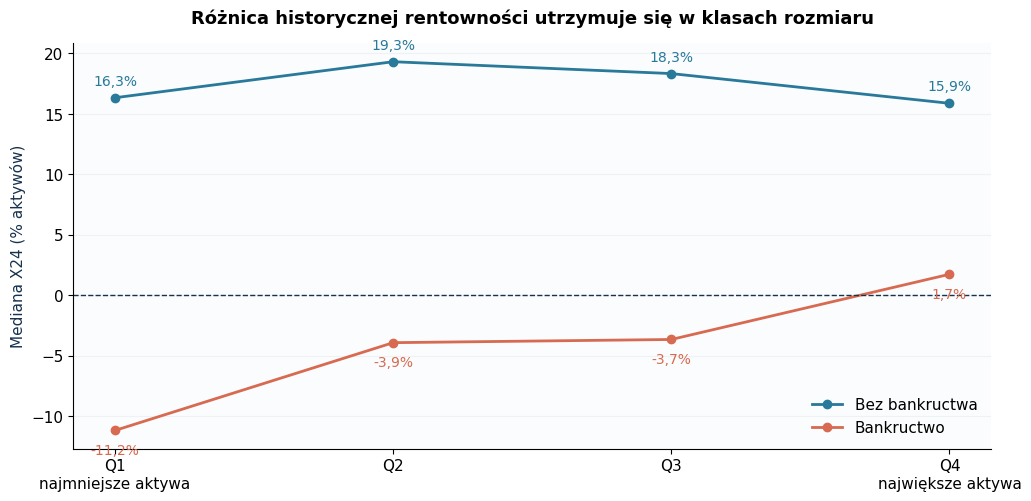

Klasa,n bez bankructwa,n bankructwo,Mediana X24: bez bankructwa,Mediana X24: bankructwo
Q1,1222,186,"16,34%","-11,19%"
Q2,1324,101,"19,31%","-3,93%"
Q3,1366,66,"18,33%","-3,66%"
Q4,1394,54,"15,87%","1,73%"


In [6]:
size_analysis=df[['X29','X24','class']].copy()
size_analysis['Kwartyl']=pd.qcut(size_analysis.X29,4,labels=['Q1','Q2','Q3','Q4'])
size_analysis=size_analysis.dropna(subset=['X29','X24','Kwartyl'])
size_summary=size_analysis.groupby(['Kwartyl','class'],observed=True).X24.agg(mediana='median',n='size')
fig,ax=plt.subplots(figsize=(10.2,4.9),layout='constrained')
for g,color,label in [(0,BLUE,'Bez bankructwa'),(1,RED,'Bankructwo')]:
    vals=np.array([size_summary.loc[(q,g),'mediana']*100 for q in ['Q1','Q2','Q3','Q4']])
    ax.plot(range(4),vals,color=color,marker='o',linewidth=2,label=label)
    for j,v in enumerate(vals):ax.annotate(pl(v,1)+'%',(j,v),xytext=(0,9 if g==0 else -17),textcoords='offset points',ha='center',fontsize=10,color=color)
ax.set_xticks(range(4),['Q1'+chr(10)+'najmniejsze aktywa','Q2','Q3','Q4'+chr(10)+'największe aktywa'])
ax.set_ylabel('Mediana X24 (% aktywów)');ax.set_title('Różnica historycznej rentowności utrzymuje się w klasach rozmiaru',pad=14)
ax.axhline(0,color=INK,linestyle='--',linewidth=1);ax.legend(frameon=False);ax.grid(axis='y',alpha=.4)
plt.show()
size_rows=[]
for q in ['Q1','Q2','Q3','Q4']:
    size_rows.append({'Klasa':q,'n bez bankructwa':int(size_summary.loc[(q,0),'n']),
      'n bankructwo':int(size_summary.loc[(q,1),'n']),
      'Mediana X24: bez bankructwa':pl(size_summary.loc[(q,0),'mediana']*100)+'%',
      'Mediana X24: bankructwo':pl(size_summary.loc[(q,1),'mediana']*100)+'%'})
table(pd.DataFrame(size_rows))




kontrola_klas_wielkosci = size_summary.copy()
kontrola_klas_wielkosci['mediana_X24_proc'] = 100 * kontrola_klas_wielkosci['mediana']
mediany_X24_w_kwartylach = size_summary['mediana'].unstack('class') * 100
roznica_median_X24 = mediany_X24_w_kwartylach[1] - mediany_X24_w_kwartylach[0]
wszystkie_mediany_bankrutow_nizsze = bool((roznica_median_X24 < 0).all())
granice_klas_X29 = df['X29'].quantile([0, .25, .5, .75, 1])
# print(kontrola_klas_wielkosci.to_string())
# print('Różnica median X24 (bankructwo minus brak bankructwa), p.p.:', roznica_median_X24.to_string())
# print('Czy mediana przy bankructwie jest niższa w każdym kwartylu?', wszystkie_mediany_bankrutow_nizsze)
# print('Granice klas X29:', granice_klas_X29.to_string())
# print('Liczba rekordów bez kompletu X29 i X24:', len(df) - len(size_analysis))

**Wnioski.** Mediana X24 jest niższa w grupie bankructw **we wszystkich czterech klasach wielkości**. W Q1 wynosi około **−11,2% wobec 16,3%**, a w Q4 **1,7% wobec 15,9%**. Różnica nie znika więc po takim prostym podziale wielkości przedsiębiorstw.

W największej klasie mediana grupy bankructw jest dodatnia. Oznacza to, że bankructwo nie musi być poprzedzone ujemnym wynikiem z szerszego okresu. Możliwe jest współwystępowanie historycznych zysków z późniejszymi problemami finansowania, ale z tych danych nie ustalamy konkretnego mechanizmu. W Q4 dostępne są tylko **54 rekordy bankructw**, wobec **186 w Q1**, więc porównań nie należy traktować jako dowodu trendu zależnego wyłącznie od rozmiaru.

## 6. Bufor krótkoterminowy: X3, X5 i X46

### Cel i zakres badania

Sprawdzono, czy grupę bankructw cechuje mniejszy bufor wobec zobowiązań krótkoterminowych. X3 odnosi kapitał obrotowy do całego majątku, X46 aktywa obrotowe bez zapasów do bieżącego długu, a X5 bufor płynnych składników do kosztów. Miary ujmują różne aspekty podobnego problemu finansowania.

Po porównaniu poziomów wskaźników oceniono częstość bankructw w trzech przedziałach X46. Umożliwia to sprawdzenie, czy niższemu względnemu pokryciu zobowiązań towarzyszy większy udział bankructw, a nie tylko niższa mediana w jednej grupie.

Wskaźnik / jednostka,n: 0 / 1,Średnia 0,Mediana 0 [Q1; Q3],Średnia 1,Mediana 1 [Q1; Q3],Efekt rangowy
X3 / % aktywów,5438 / 407,"23,11","23,26 [6,25; 42,68]","-38,40","-1,31 [-30,35; 23,88]","-0,415"
X5 / wg wzoru UCI,5427 / 408,"227,09","3,54 [-39,20; 51,55]","-2 766,11","-56,71 [-133,11; -0,71]","-0,401"
X46 / razy,5420 / 402,"4,05","1,12 [0,68; 2,03]","3,60","0,47 [0,21; 0,85]","-0,501"


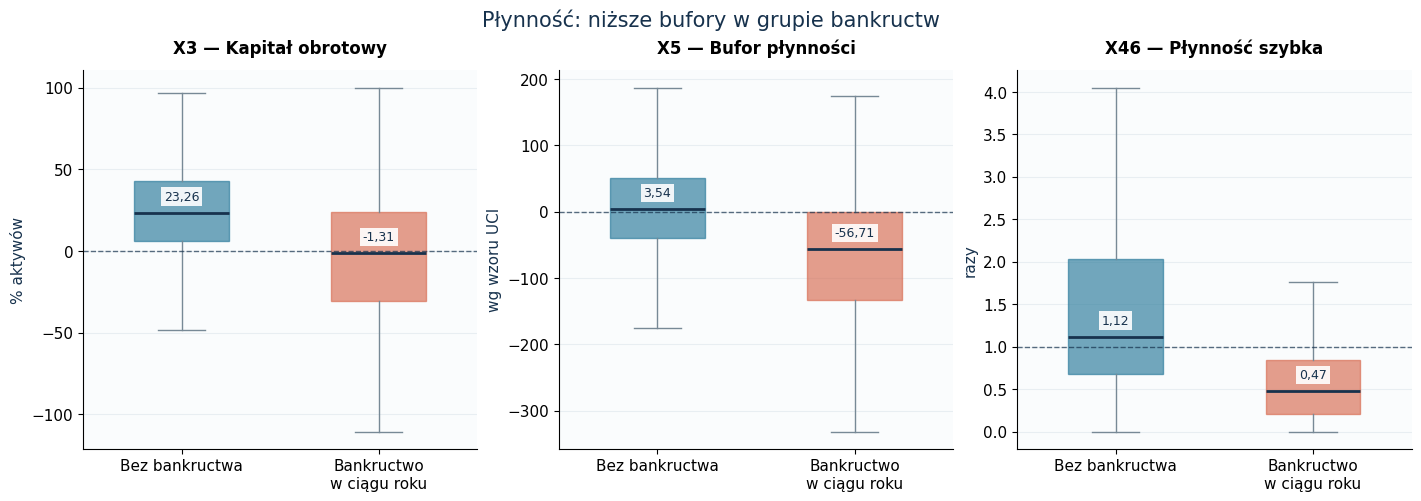

In [7]:
group_table(GROUPS['Płynność'])
fig, axes = plt.subplots(1, 3, figsize=(14.1, 4.9), layout='constrained')
for ax, c in zip(axes, GROUPS['Płynność']):
    box_panel(ax, c)
fig.suptitle('Płynność: niższe bufory w grupie bankructw', fontsize=15, color=INK)
plt.show()




kontrola_plynnosci_stat = KONTROLA_STATYSTYK.loc[GROUPS['Płynność'], ['n_dostepnych', 'jednostka', 'srednia', 'mediana', 'Q1', 'Q3', 'n_ujemnych', 'ujemne_proc']]
# print(kontrola_plynnosci_stat.to_string())

**X3 — kapitał obrotowy.** Mediana wynosi **23,26%** i **-1,31% aktywów**. Ujemna mediana przy bankructwie oznacza, że co najmniej połowa dostępnych wyników znajduje się po stronie niedoboru aktywów obrotowych wobec zobowiązań krótkoterminowych. Nie utożsamiamy całych aktywów obrotowych z natychmiast dostępną gotówką.

**X5 — bufor wobec kosztów.** Mediany **3,54** i **-56,71** pokazują wyraźne przesunięcie wyników. To spójne z mniejszym buforem finansowania, lecz nie odczytujemy wartości jako liczby dni do upadłości. Bez licznika i mianownika nie rozdzielimy wpływu płynnych aktywów, zobowiązań i poziomu kosztów.

**X46 — płynność szybka.** Mediany **1,12** i **0,47** wskazują na słabsze pokrycie bieżącego długu aktywami obrotowymi bez zapasów. Nawet wynik przekraczający 1 nie zapewnia spłaty, jeśli należności są nieściągalne lub terminy wpływów nie odpowiadają terminom płatności. Zgodny kierunek trzech miar jest informacyjny, ale wspólne składniki wzorów ograniczają ich niezależność.

### Stopień pokrycia bieżących zobowiązań a bankructwo

Przedziały X46 oznaczają pokrycie mniej niż połowy zobowiązań, co najmniej połowy, ale mniej niż całości, oraz co najmniej całości przez aktywa obrotowe bez zapasów. Są to progi interpretacyjne, nie normy dla wszystkich branż i nie progi dobrane pod skuteczność modelu. Udział bankructw obliczono wewnątrz każdego przedziału; podano liczebności i 95% przedziały Wilsona.

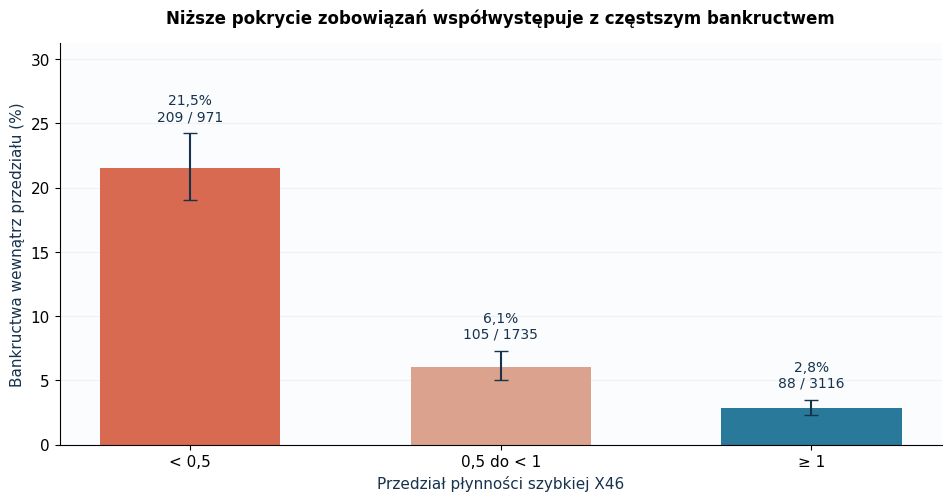

In [8]:
liquidity_analysis=df[['X46','class']].dropna().copy()
liquidity_analysis['Przedział']=pd.cut(liquidity_analysis.X46,[-np.inf,.5,1,np.inf],right=False,labels=['< 0,5','0,5 do < 1','≥ 1'])
liq=liquidity_analysis.groupby('Przedział',observed=True)['class'].agg(n='size',bankructwa='sum')
liq['p']=liq.bankructwa/liq.n
z=1.959963984540054;ns=liq.n.to_numpy();ps=liq.p.to_numpy()
center=(ps+z*z/(2*ns))/(1+z*z/ns);half=z*np.sqrt(ps*(1-ps)/ns+z*z/(4*ns*ns))/(1+z*z/ns)
fig,ax=plt.subplots(figsize=(9.4,4.9),layout='constrained')
ax.bar(range(3),ps*100,color=[RED,'#DBA38D',BLUE],width=.58)
ax.errorbar(range(3),ps*100,yerr=np.vstack([ps-center+half,center+half-ps])*100,fmt='none',ecolor=INK,capsize=5)
for j,row in enumerate(liq.itertuples()):ax.text(j,(center[j]+half[j])*100+1,pl(row.p*100,1)+'%'+chr(10)+str(row.bankructwa)+' / '+str(row.n),ha='center',fontsize=10,color=INK)
ax.set_xticks(range(3),liq.index.astype(str));ax.set_xlabel('Przedział płynności szybkiej X46')
ax.set_ylabel('Bankructwa wewnątrz przedziału (%)');ax.set_ylim(0,(center+half).max()*100+7)
ax.set_title('Niższe pokrycie zobowiązań współwystępuje z częstszym bankructwem',fontsize=12,pad=14)
ax.grid(axis='y',alpha=.4);ax.set_axisbelow(True)
plt.show()




kontrola_przedzialow_X46 = liq.copy()
kontrola_przedzialow_X46['odsetek_bankructw_proc'] = 100 * kontrola_przedzialow_X46['bankructwa'] / kontrola_przedzialow_X46['n']
kontrola_przedzialow_X46['dol_95_proc'] = 100 * (center - half)
kontrola_przedzialow_X46['gora_95_proc'] = 100 * (center + half)
# print(kontrola_przedzialow_X46.to_string())
# print('Brak X46 — rekordy poza tym podziałem:', len(df) - len(liquidity_analysis))

**Wnioski.** Udział bankructw wynosi **21,5%** przy X46 poniżej 0,5, **6,1%** w przedziale od 0,5 do mniej niż 1 oraz **2,8%** przy X46 co najmniej równym 1. Niższy względny bufor płynności wiąże się zatem z większą częstością bankructw w tej próbie.

Nie oznacza to, że wszystkie aktywa obrotowe bez zapasów są natychmiast dostępne lub że X46 ≥ 1 gwarantuje spłatę. Należności mogą być trudno ściągalne, a terminy wpływów różne od terminów zapadalności długu. Także w grupie najniższego pokrycia większość rekordów nie kończy się bankructwem; jest to sygnał trudności, a nie deterministyczna reguła.

## 7. Zadłużenie i koszty: X2, X34, X58 i X62

### Cel i zakres badania

Sprawdzono, jak zobowiązania i koszty obciążają majątek oraz sprzedaż. X2 ujmuje całkowite zadłużenie względem aktywów, a X62 zobowiązania krótkoterminowe względem sprzedaży. X58 określa kosztochłonność sprzedaży, natomiast X34 relację kosztów operacyjnych do zobowiązań. Wspólne omówienie pozwala odróżnić obciążenie długiem od problemu kosztów przewyższających sprzedaż.

Uzupełniająco oceniono, czy jednoczesna przewaga zobowiązań nad aktywami i kosztów nad sprzedażą wiąże się z większą częstością bankructw niż występowanie tylko jednego z tych zjawisk.

Wskaźnik / jednostka,n: 0 / 1,Średnia 0,Mediana 0 [Q1; Q3],Średnia 1,Mediana 1 [Q1; Q3],Efekt rangowy
X2 / % aktywów,5437 / 407,"48,90","43,61 [25,08; 64,31]","122,00","72,48 [47,83; 97,68]","0,432"
X34 / razy,5427 / 405,"4,86","1,72 [0,25; 4,08]","7,37","1,71 [0,28; 3,54]","-0,034"
X58 / % sprzedaży,5433 / 408,"94,24","94,69 [87,51; 98,72]","116,98","100,79 [95,07; 113,86]","0,421"
X62 / dni wg wzoru,5438 / 407,"144,94","71,68 [43,87; 113,87]","1 564,60","125,57 [71,86; 242,51]","0,394"


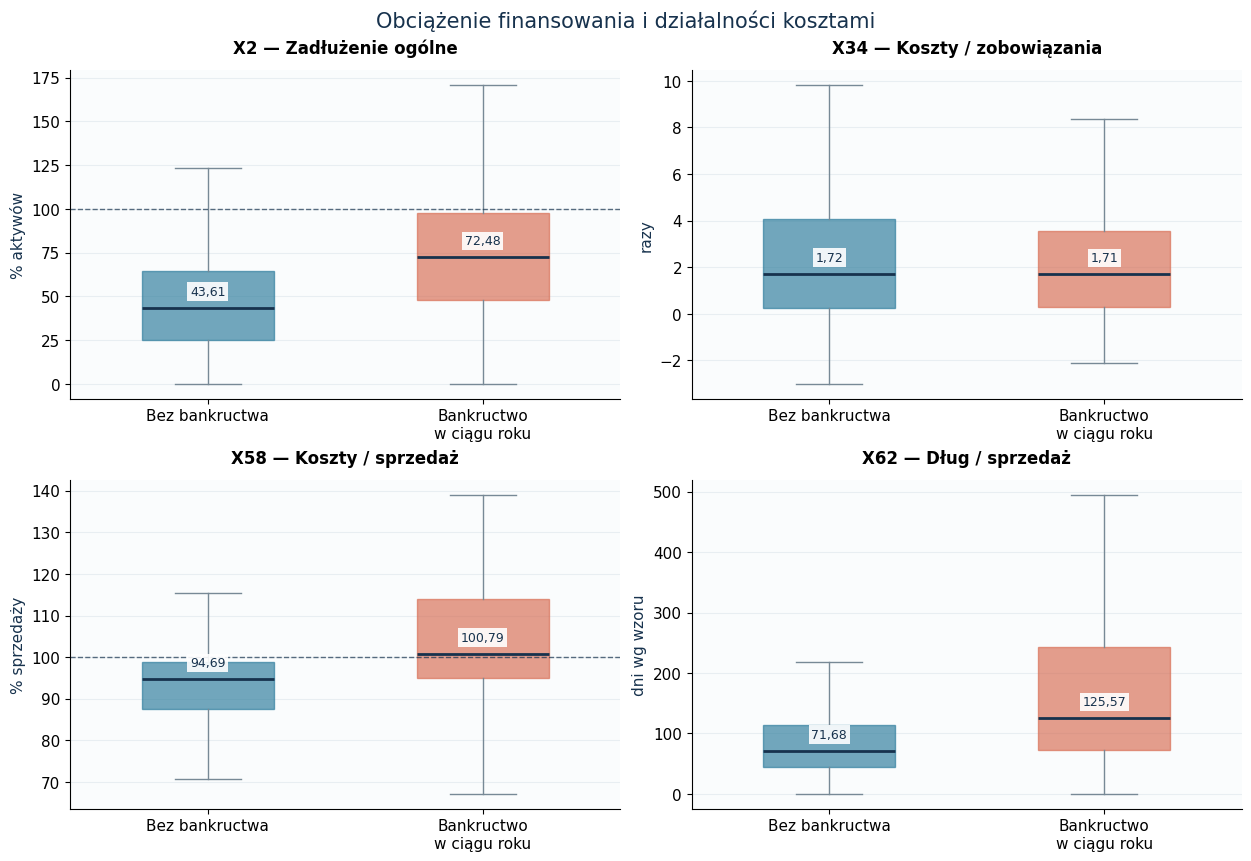

In [9]:
group_table(GROUPS['Zadłużenie i koszty'])
fig, axes = plt.subplots(2, 2, figsize=(12.4, 8.5), layout='constrained')
for ax, c in zip(axes.flat, GROUPS['Zadłużenie i koszty']):
    box_panel(ax, c)
fig.suptitle('Obciążenie finansowania i działalności kosztami', fontsize=15, color=INK)
plt.show()




kontrola_obciazen_stat = KONTROLA_STATYSTYK.loc[GROUPS['Zadłużenie i koszty'], ['n_dostepnych', 'jednostka', 'srednia', 'mediana', 'Q1', 'Q3', 'efekt_rangowy']]
# print(kontrola_obciazen_stat.to_string())
# print('Efekt rangowy X34:', EFFECT['X34'])

**X2 — zadłużenie majątku.** Mediany **43,61%** i **72,48% aktywów** wskazują na większe względne obciążenie zobowiązaniami przy bankructwie. Wynik ponad 100% jest możliwy i sygnalizuje zobowiązania przewyższające majątek. Nie dowodzi jednak, kiedy i czy firma utraci zdolność regulowania płatności.

**X34 — koszty do długu.** Mediany **1,721** i **1,706** oraz zbliżone pudełka nie pokazują silnego prostego rozdzielenia grup (efekt rangowy **-0,034**). Większa wartość może wynikać zarówno z wysokich kosztów, jak i małego długu. Nie opisujemy jej automatycznie jako dobrej lub złej. Silna zależność z inną cechą również nie oznaczałaby silnej różnicy między klasami.

**X58 — koszty do sprzedaży.** Mediany **94,69%** i **100,79% sprzedaży** pokazują przekroczenie 100% w typowym rekordzie grupy bankructw. To ekonomicznie spójne z mniejszą nadwyżką na obsługę finansowania i odbudowę kapitału. Nie określamy jednak bez źródłowych sprawozdań struktury kosztów ani przepływów gotówkowych.

**X62 — dług wobec sprzedaży.** Mediany wynoszą **71,68** i **125,57** w jednostkach dni wynikających ze wzoru. Większe obciążenie w grupie bankructw może oznaczać zarówno większy dług krótkoterminowy, jak i mniejszą sprzedaż. To nie jest średni rzeczywisty termin zapłaty ani liczba dni potrzebna do spłaty z zysku.

### Współwystępowanie obciążenia zadłużeniem i kosztami

Warunek X2 > 1 oznacza zobowiązania przewyższające aktywa, a X58 > 1 koszty przekraczające sprzedaż. Podział wykorzystuje znaczenie ekonomiczne tych proporcji. W czterech grupach obliczono udział bankructw i liczbę rekordów; nie traktujemy tych udziałów jako prognoz dla nowych przedsiębiorstw.

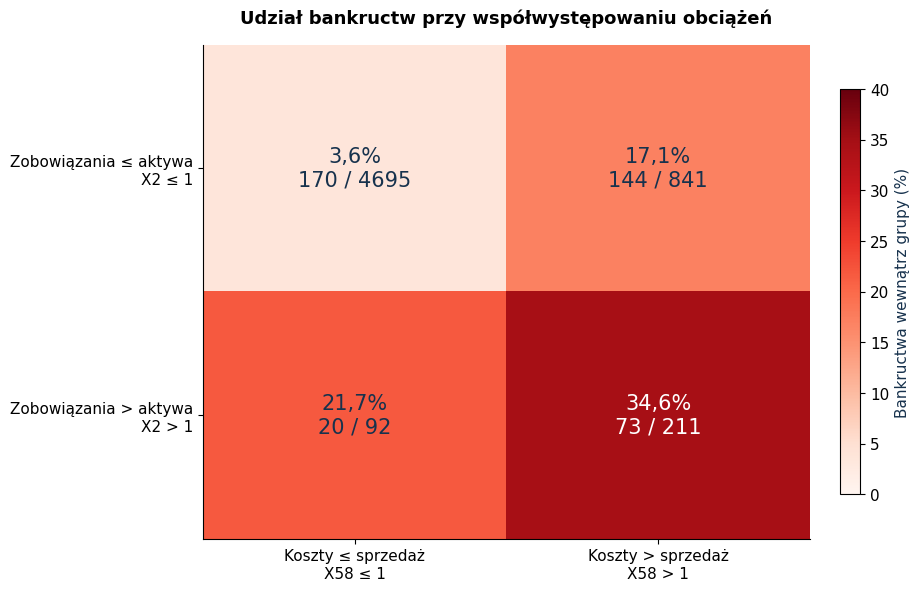

In [10]:
burden=df[['X2','X58','class']].dropna().copy()
burden['Dług ponad aktywa']=burden.X2>1;burden['Koszty ponad sprzedaż']=burden.X58>1
burden_summary=burden.groupby(['Dług ponad aktywa','Koszty ponad sprzedaż'])['class'].agg(n='size',bankructwa='sum')
rates=np.zeros((2,2))
for i,debt in enumerate([False,True]):
    for j,cost in enumerate([False,True]):
        row=burden_summary.loc[(debt,cost)];rates[i,j]=row.bankructwa/row.n*100
fig,ax=plt.subplots(figsize=(9.1,5.8),layout='constrained')
img=ax.imshow(rates,cmap='Reds',vmin=0,vmax=40,aspect='auto')
for i,debt in enumerate([False,True]):
    for j,cost in enumerate([False,True]):
        row=burden_summary.loc[(debt,cost)]
        label=pl(rates[i,j],1)+'%'+chr(10)+str(int(row.bankructwa))+' / '+str(int(row.n))
        ax.text(j,i,label,ha='center',va='center',fontsize=15,color='white' if rates[i,j]>22 else INK)
ax.set_xticks([0,1],['Koszty ≤ sprzedaż'+chr(10)+'X58 ≤ 1','Koszty > sprzedaż'+chr(10)+'X58 > 1'])
ax.set_yticks([0,1],['Zobowiązania ≤ aktywa'+chr(10)+'X2 ≤ 1','Zobowiązania > aktywa'+chr(10)+'X2 > 1'])
ax.set_title('Udział bankructw przy współwystępowaniu obciążeń',pad=15)
cb=fig.colorbar(img,ax=ax,shrink=.82);cb.set_label('Bankructwa wewnątrz grupy (%)')
plt.show()




kontrola_dlugu_i_kosztow = burden_summary.copy()
kontrola_dlugu_i_kosztow['odsetek_bankructw_proc'] = 100 * kontrola_dlugu_i_kosztow['bankructwa'] / kontrola_dlugu_i_kosztow['n']
najmniejsza_grupa_obciazen = int(kontrola_dlugu_i_kosztow['n'].min())
# print(kontrola_dlugu_i_kosztow.to_string())
# print('Najmniejsza liczebność grupy:', najmniejsza_grupa_obciazen)
# print('Przy obu warunkach:', int(burden_summary.loc[(True, True), 'bankructwa']), '/', int(burden_summary.loc[(True, True), 'n']))
# print('Rekordy bez kompletu X2 i X58:', len(df) - len(burden))

**Wnioski.** Przy zobowiązaniach nieprzewyższających aktywów i kosztach nieprzekraczających sprzedaży bankructwa stanowią **3,6%** grupy. Udział rośnie do **17,1%** przy samej przewadze kosztów oraz do **21,7%** przy samej przewadze zobowiązań. Przy obu zjawiskach wynosi **34,6%** (**73 z 211 rekordów**).

Zestawienie jest spójne z kumulacją problemów: mniejszy bufor majątkowy współwystępuje z brakiem nadwyżki sprzedaży nad kosztami. Nie dowodzi to efektu przyczynowego ani statystycznej interakcji obu warunków. Najmniejsza z czterech grup ma **92 rekordy**, więc wielkości różnic należy czytać z uwzględnieniem liczebności. X34 i X62 uzupełniają opis struktury obciążeń, lecz ich wysokie wartości nie mają tak samo jednoznacznej interpretacji jak przekroczenie 1 przez X2 i X58.

## 8. Współzależności wszystkich 13 wskaźników

### Cel badania

Oceniono, które miary opisują zbliżone aspekty kondycji finansowej, a które dostarczają odmiennych informacji. Zastosowano korelację rang Spearmana dla wszystkich par oraz osobno w obu grupach. Pozwala to oddzielić opis wspólnego uporządkowania wyników od różnic w poziomie między klasami. Korelacje nie określają samodzielnej przydatności predykcyjnej ani związku przyczynowego.

Partnerów w tabeli interpretacyjnej przypisano według znaczenia finansowego: poziomy rentowności, historia wyników, wielkość, płynność i obciążenie zobowiązaniami. Powtórzenie pary przy obu wskaźnikach nie jest odrębnym wynikiem.

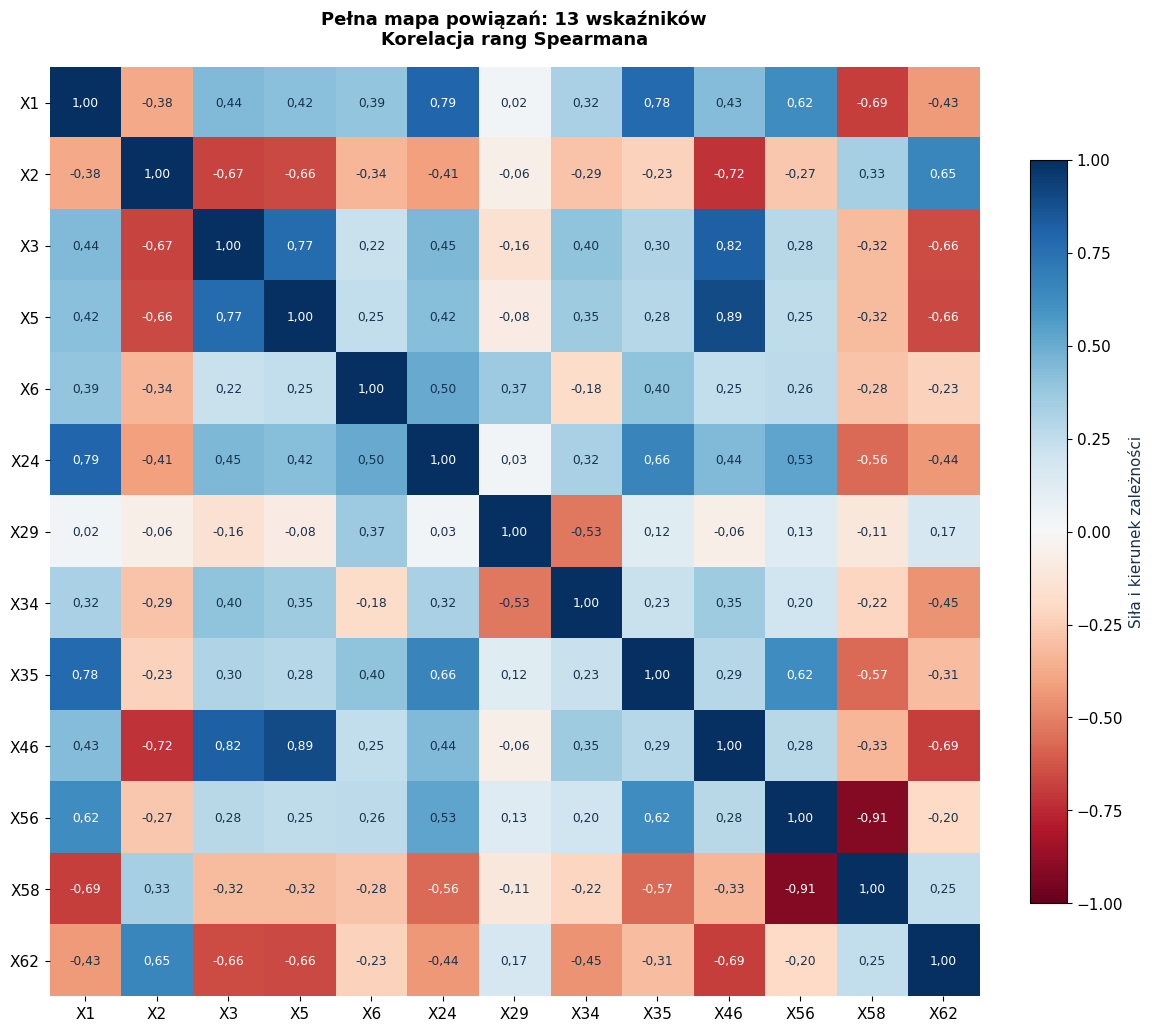

In [11]:
CORR = df[FEATURES].corr(method='spearman')
CORR_GROUP = {g: df.loc[df['class'] == g, FEATURES].corr(method='spearman') for g in [0, 1]}
fig, ax = plt.subplots(figsize=(11.9, 10.2), layout='constrained')
img = ax.imshow(CORR.to_numpy(), vmin=-1, vmax=1, cmap='RdBu')
ax.set_xticks(range(len(FEATURES)), FEATURES)
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        v = CORR.iloc[i, j]
        ax.text(j, i, pl(v, 2), ha='center', va='center', color='white' if abs(v) > 0.55 else INK, fontsize=8.8)
ax.set_title('Pełna mapa powiązań: 13 wskaźników' + chr(10) + 'Korelacja rang Spearmana', pad=16)
ax.spines[['top', 'right', 'bottom', 'left']].set_visible(False)
cb = fig.colorbar(img, ax=ax, shrink=0.8)
cb.set_label('Siła i kierunek zależności')
plt.show()




kontrola_n_par = df[FEATURES].notna().astype(int).T.dot(df[FEATURES].notna().astype(int))
# print(CORR.round(3).to_string())
# print('Liczba wspólnych obserwacji każdej pary:', kontrola_n_par.to_string())
# print('Korelacje bez bankructwa:', CORR_GROUP[0].round(3).to_string())
# print('Korelacje przy bankructwie:', CORR_GROUP[1].round(3).to_string())

**Wniosek z mapy.** Widać grupy powiązań rentowności, płynności oraz marży i kosztów. To uzasadnia tematyczny układ analizy, ale nie oznacza, że kolejne wskaźniki są niezależnymi dowodami. Dokładny sens każdej z 13 cech omawiamy poniżej, również przy słabszych zależnościach.

In [12]:
PARTNERS = {'X1': 'X35', 'X2': 'X46', 'X3': 'X46', 'X5': 'X46', 'X6': 'X24', 'X24': 'X1', 'X29': 'X6', 'X34': 'X2', 'X35': 'X1', 'X46': 'X62', 'X56': 'X58', 'X58': 'X56', 'X62': 'X2'}
rows = []
for c in FEATURES:
    other = PARTNERS[c]
    rows.append({'Wskaźnik': c, 'Partner': other, 'rho: całość': pl(CORR.loc[c, other], 3), 'rho: bez bankructwa': pl(CORR_GROUP[0].loc[c, other], 3), 'rho: bankructwo': pl(CORR_GROUP[1].loc[c, other], 3), 'Wspólne n': int(df[[c, other]].notna().all(axis=1).sum())})
table(pd.DataFrame(rows))
for c in FEATURES:
    other = PARTNERS[c]




kontrola_korelacji_wiersze = []
for wskaznik, partner in PARTNERS.items():
    kontrola_korelacji_wiersze.append({'Wskaznik': wskaznik, 'Partner': partner,
        'rho_calosc': CORR.loc[wskaznik, partner],
        'rho_bez_bankructwa': CORR_GROUP[0].loc[wskaznik, partner],
        'rho_bankructwo': CORR_GROUP[1].loc[wskaznik, partner],
        'n_pary': int(df[[wskaznik, partner]].notna().all(axis=1).sum())})
KONTROLA_KORELACJI = pd.DataFrame(kontrola_korelacji_wiersze)
# print(KONTROLA_KORELACJI.to_string(index=False))

Wskaźnik,Partner,rho: całość,rho: bez bankructwa,rho: bankructwo,Wspólne n
X1,X35,"0,780","0,762","0,842",5845
X2,X46,"-0,724","-0,714","-0,652",5822
X3,X46,"0,819","0,809","0,806",5822
X5,X46,"0,891","0,900","0,662",5811
X6,X24,"0,503","0,495","0,430",5713
X24,X1,"0,790","0,799","0,718",5713
X29,X6,"0,365","0,353","0,256",5845
X34,X2,"-0,287","-0,288","-0,313",5830
X35,X1,"0,780","0,762","0,842",5845
X46,X62,"-0,689","-0,688","-0,530",5822


**X1 z X35 — rho = 0,780.** Wynik netto i wynik na sprzedaży odnoszą się do tych samych aktywów. Zgodny kierunek jest spójny z rolą podstawowej działalności, ale wspólny mianownik sam wzmacnia powiązanie. Nie są to dwie niezależne miary.

**X2 z X46 — rho = -0,724.** Większemu względnemu zadłużeniu zwykle towarzyszy słabsza płynność szybka. Łączy to obciążenie całego majątku z buforem krótkoterminowym; różne terminy długu nie pozwalają utożsamić tych relacji.

**X3 z X46 — rho = 0,819.** Kapitał obrotowy i płynność szybka wykorzystują aktywa obrotowe oraz zobowiązania krótkoterminowe. Zależność jest częściowo związana z konstrukcją wzorów; zapasy i inny mianownik powodują, że nie są identyczne.

**X5 z X46 — rho = 0,891.** Miara bufora wobec kosztów jest silnie powiązana z płynnością szybką. Zależność jest słabsza w grupie bankructw, co opisowo wskazuje na bardziej zróżnicowane relacje kosztów i aktywów. Bez testu nie stwierdzamy istotnej różnicy korelacji.

**X6 z X24 — rho = 0,503.** Wynik zatrzymany i wynik z trzech lat opisują historię zysków, ale różne pozycje i okresy. Umiarkowana zgodność nie daje podstaw do traktowania jednej miary jako dokładnego zamiennika drugiej.

**X24 z X1 — rho = 0,790.** Związek z bieżącym wynikiem netto jest spójny z utrzymywaniem się różnic rentowności w szerszej perspektywie. Obie miary odnoszą się do aktywów; nie potwierdzamy kolejności strat ani pogarszania się sytuacji rok po roku.

**X29 z X6 — rho = 0,365.** Większe aktywa współwystępują z wyższym wynikiem zatrzymanym względem aktywów. Akumulacja kapitału może wiązać się z historią działalności, lecz bez wieku i branży jest to hipoteza, nie ustalony mechanizm.

**X34 z X2 — rho = -0,287.** Ujemna relacja z zadłużeniem ma częściowo sens konstrukcyjny: zobowiązania są mianownikiem X34 i licznikiem X2. Samo współdzielenie tej pozycji może tworzyć zależność; nie oznacza, że wysokie X34 chroni przed bankructwem.

**X35 z X1 — rho = 0,780.** Powiązanie z wynikiem netto potwierdza, że obie miary porządkują firmy podobnie. Różnica między nimi może zależeć od pozostałych pozycji wyniku. Bez tych pozycji nie przypisujemy rozbieżności wyłącznie odsetkom lub podatkom.

**X46 z X62 — rho = -0,689.** Przy wyższym długu krótkoterminowym wobec sprzedaży zwykle spada płynność szybka. Wspólny składnik zobowiązań działa tu w przeciwnych miejscach wzorów, więc część ujemnej zależności ma charakter konstrukcyjny.

**X56 z X58 — rho = -0,914.** Wyższa marża zwykle współwystępuje z niższą kosztochłonnością ogółem. Nie zakładamy tożsamości X56 = 1 − X58: formuły odnoszą się do różnych zakresów kosztów i sprzedaży.

**X58 z X56 — rho = -0,914.** Kosztochłonność i marża pokazują przeciwne strony relacji przychodów do kosztów. Silny ujemny związek jest spójny ekonomicznie, ale nie oznacza, że obie cechy zawsze dostarczają modelowi identycznej informacji.

**X62 z X2 — rho = 0,651.** Dług krótkoterminowy do sprzedaży rośnie zwykle wraz z zadłużeniem ogółem do majątku. Miary odnoszą się jednak do różnych skal działalności, więc porównanie odróżnia obciążenie sprzedaży od obciążenia majątku.

**Uwaga do tabeli.** Partnerów wybrano ze względu na pytanie ekonomiczne, nie automatycznie według największego współczynnika. Powtórzenie pary przy obu jej wskaźnikach nie jest drugim niezależnym wynikiem. Korelacje wewnątrz klas mają różne liczebności; same różnice liczb nie dowodzą zmiany mechanizmu finansowego.

## 9. Zależności między poziomami wyniku, finansowaniem i kosztami

Uzupełnieniem korelacji jest ocena kształtu zależności czterech par. X1–X35 zestawia wynik netto z wynikiem na sprzedaży; X2–X46 obciążenie majątku długiem z płynnością; X56–X58 marżę z kosztochłonnością; X34–X2 iloraz kosztów do długu z relacją długu do aktywów. Celem jest sprawdzenie rozrzutu i nakładania się wyników klas, których pojedynczy współczynnik nie pokazuje.

Zakresy osi ograniczono do 1.–99. percentyla każdej zmiennej wyłącznie na potrzeby prezentacji. Korelacje obliczono na wszystkich wspólnie dostępnych wynikach. Tabela podaje liczby obserwacji widocznych w centralnym zakresie. Różne liczebności klas nie pozwalają interpretować gęstości punktów jako częstości bankructwa.

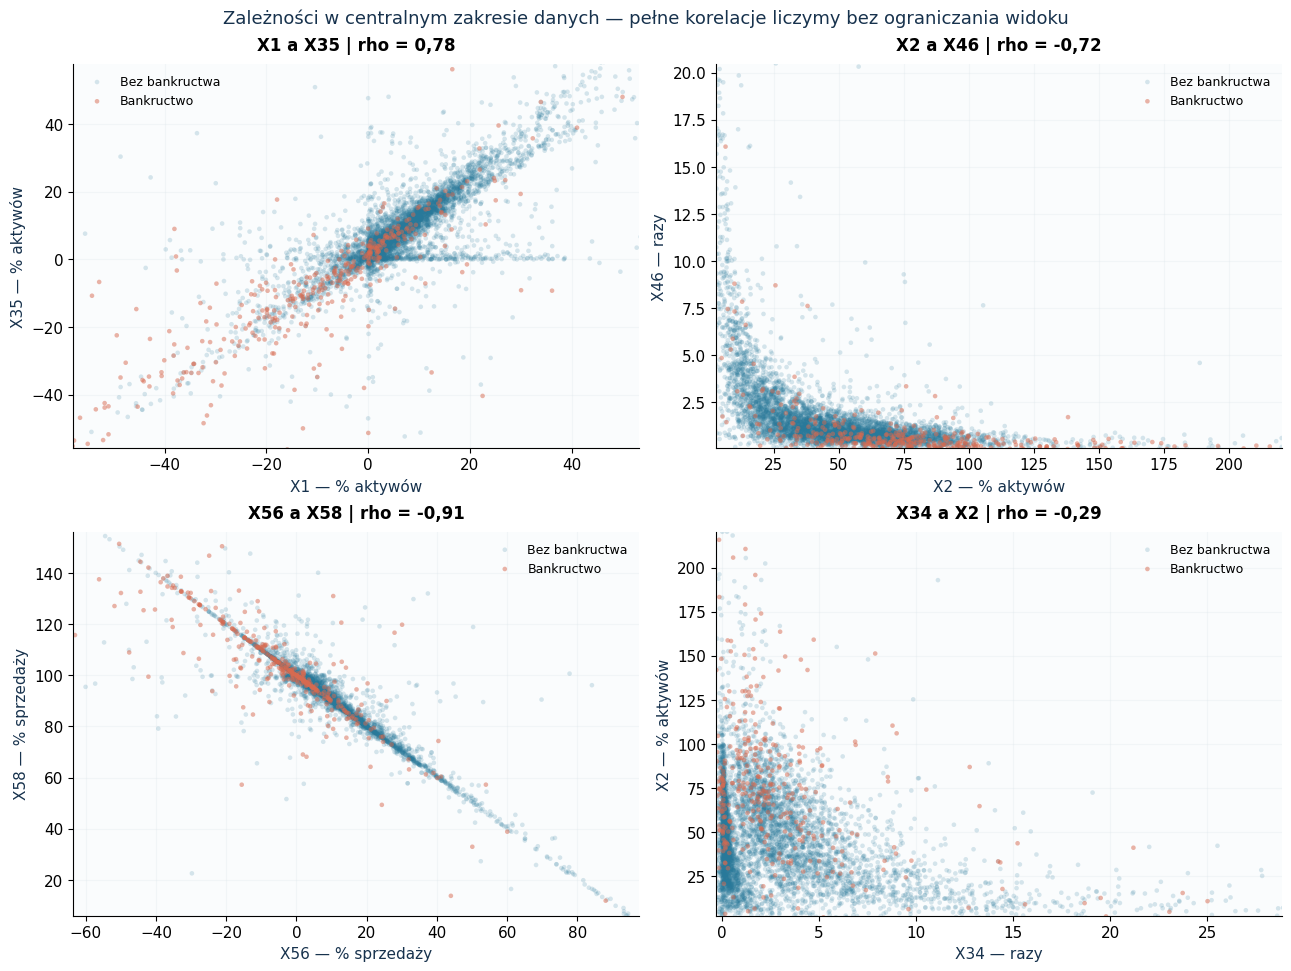

Para,Pełne wspólne n,Widoczne: bez bankructwa,Widoczne: bankructwo
X1–X35,5845,5330,360
X2–X46,5822,5297,344
X56–X58,5841,5322,373
X34–X2,5830,5278,344


In [13]:
scatter_pairs = [('X1', 'X35'), ('X2', 'X46'), ('X56', 'X58'), ('X34', 'X2')]
fig, axes = plt.subplots(2, 2, figsize=(12.8, 9.6), layout='constrained')
visible = []
for ax, (cx, cy) in zip(axes.flat, scatter_pairs):
    fx = UNITS[cx][1]
    fy = UNITS[cy][1]
    complete = df[[cx, cy, 'class']].dropna()
    x = complete[cx] * fx
    y = complete[cy] * fy
    xlo, xhi = x.quantile([0.01, 0.99])
    ylo, yhi = y.quantile([0.01, 0.99])
    mask = x.between(xlo, xhi) & y.between(ylo, yhi)
    for g, color, label in [(0, BLUE, 'Bez bankructwa'), (1, RED, 'Bankructwo')]:
        rows = complete['class'] == g
        ax.scatter(x[rows], y[rows], s=11, color=color, alpha=0.18 if g == 0 else 0.5, edgecolors='none', label=label)
    ax.set_xlim(xlo, xhi)
    ax.set_ylim(ylo, yhi)
    ax.set_xlabel(cx + ' — ' + UNITS[cx][0])
    ax.set_ylabel(cy + ' — ' + UNITS[cy][0])
    ax.set_title(cx + ' a ' + cy + ' | rho = ' + pl(CORR.loc[cx, cy], 2), fontsize=12, pad=10)
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=9, loc='best')
    n0 = int((mask & (complete['class'] == 0)).sum())
    n1 = int((mask & (complete['class'] == 1)).sum())
    visible.append({'Para': cx + '–' + cy, 'Pełne wspólne n': len(complete), 'Widoczne: bez bankructwa': n0, 'Widoczne: bankructwo': n1})
fig.suptitle('Zależności w centralnym zakresie danych — pełne korelacje liczymy bez ograniczania widoku', fontsize=13, color=INK)
plt.show()
table(pd.DataFrame(visible))




kontrola_widocznych = pd.DataFrame(visible)
# print(kontrola_widocznych.to_string(index=False))
# print(KONTROLA_KORELACJI.loc[KONTROLA_KORELACJI['Wskaznik'].isin(['X1', 'X2', 'X56', 'X34'])].to_string(index=False))

**Wnioski z par.** X1–X35 pokazuje zgodność dwóch poziomów rentowności, ale także rozbieżności; jeden wynik nie odtwarza dokładnie drugiego. Dla X2–X46 widać ujemny kierunek, lecz firmy o podobnym zadłużeniu mają różną płynność — znaczenie ma struktura aktywów i długu. X56–X58 tworzy silnie malejącą zależność, spójną z relacją marży do kosztów, bez zakładania dokładnej tożsamości wzorów. X34–X2 ma słabszą monotoniczną zależność i duży rozrzut, co utrudnia nadanie X34 jednej interpretacji. Nakładanie się kolorów w każdej parze potwierdza, że dwa wskaźniki nie tworzą prostego, pełnego podziału firm.

## 10. Połączenie wyniku i finansowania krótkoterminowego

### Cel badania

Sprawdzono, czy strata netto współwystępująca z ujemnym kapitałem obrotowym wiąże się z większą częstością bankructw niż pojedynczy sygnał. X1 < 0 odnosi się do wyniku, a X3 < 0 do niedoboru aktywów obrotowych wobec zobowiązań krótkoterminowych. Są to dwa różne aspekty trudności, mimo częściowej zależności między wskaźnikami.

W każdej z czterech grup wyznaczono udział bankructw, liczebność i 95% przedział Wilsona. Progi zero wynikają z definicji wskaźników, nie z optymalizacji modelu.

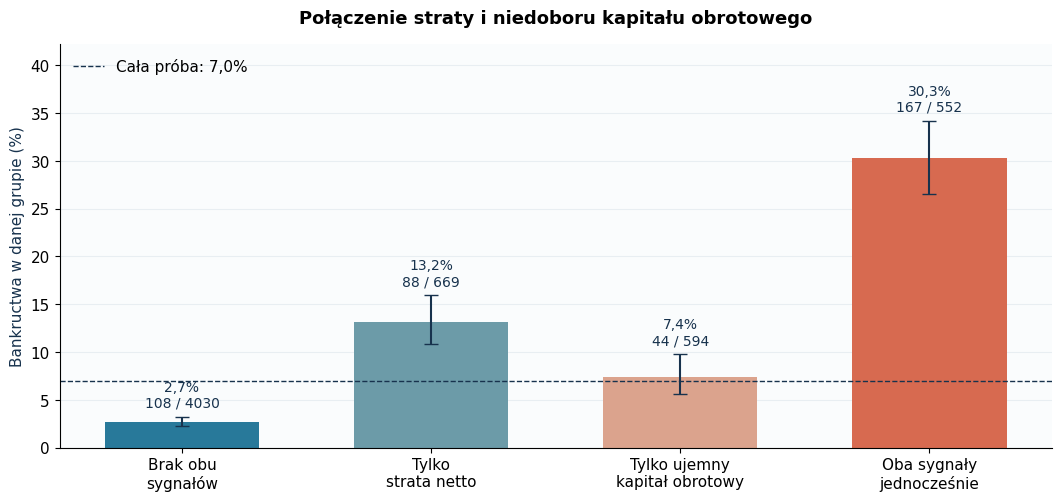

In [14]:
valid = df.dropna(subset=['X1', 'X3']).copy()
loss = valid.X1 < 0
shortage = valid.X3 < 0
valid['grupa'] = np.select([~loss & ~shortage, loss & ~shortage, ~loss & shortage, loss & shortage], [0, 1, 2, 3], default=-1)
groups = valid.groupby('grupa')['class'].agg(n='size', bankructwa='sum').reindex(range(4))
groups['p'] = groups.bankructwa / groups.n
z = 1.959963984540054
p0 = groups.p.to_numpy()
ns = groups.n.to_numpy()
center = (p0 + z * z / (2 * ns)) / (1 + z * z / ns)
half = z * np.sqrt(p0 * (1 - p0) / ns + z * z / (4 * ns * ns)) / (1 + z * z / ns)
groups['dol'] = center - half
groups['gora'] = center + half
fig, ax = plt.subplots(figsize=(10.5, 4.9), layout='constrained')
nl = chr(10)
labels = ['Brak obu' + nl + 'sygnałów', 'Tylko' + nl + 'strata netto', 'Tylko ujemny' + nl + 'kapitał obrotowy', 'Oba sygnały' + nl + 'jednocześnie']
ax.bar(range(4), p0 * 100, color=[BLUE, '#6C9BA8', '#DBA38D', RED], width=0.62)
ax.errorbar(range(4), p0 * 100, yerr=np.vstack([p0 - groups.dol, groups.gora - p0]) * 100, fmt='none', ecolor=INK, capsize=5)
for j, row in groups.iterrows():
    ax.text(j, row.gora * 100 + 1, pl(row.p * 100, 1) + '%' + nl + str(int(row.bankructwa)) + ' / ' + str(int(row.n)), ha='center', fontsize=10, color=INK)
ax.axhline(df['class'].mean() * 100, color=INK, linestyle='--', linewidth=1, label='Cała próba: ' + pl(df['class'].mean() * 100, 1) + '%')
ax.set_xticks(range(4), labels)
ax.set_ylabel('Bankructwa w danej grupie (%)')
ax.set_ylim(0, groups.gora.max() * 100 + 8)
ax.set_title('Połączenie straty i niedoboru kapitału obrotowego', pad=15)
ax.grid(axis='y', alpha=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper left')
plt.show()
ratio = groups.loc[3, 'p'] / groups.loc[0, 'p']




kontrola_sygnalow = groups.copy()
kontrola_sygnalow['odsetek_bankructw_proc'] = 100 * kontrola_sygnalow['bankructwa'] / kontrola_sygnalow['n']
kontrola_sygnalow['dol_95_proc'] = 100 * kontrola_sygnalow['dol']
kontrola_sygnalow['gora_95_proc'] = 100 * kontrola_sygnalow['gora']
krotnosc_czestosci = groups.loc[3, 'p'] / groups.loc[0, 'p']
rekordy_pominiete_X1_X3 = len(df) - len(valid)
# print('Grupy: 0 — brak obu; 1 — tylko strata; 2 — tylko ujemny kapitał obrotowy; 3 — oba sygnały')
# print(kontrola_sygnalow.to_string())
# print('Iloraz udziałów bankructw =', groups.loc[3, 'p'], '/', groups.loc[0, 'p'], '=', pl(krotnosc_czestosci, 1))
# print('Rekordy bez X1 lub X3:', rekordy_pominiete_X1_X3)

**Interpretacja.** Przy obu sygnałach udział bankructw wynosi **30,3%**, wobec **2,7%** przy braku obu — około **11,3 razy** więcej. Strata ogranicza odbudowę finansowania z wyniku, a ujemny kapitał obrotowy oznacza mniejszy bufor wobec bieżących zobowiązań. Połączenie jest więc spójne z większą podatnością na trudności, lecz nie jest dowodem przyczynowym. Nawet przy obu sygnałach większość rekordów nie kończy się bankructwem; brak obu również nie oznacza zerowego zagrożenia. Liczba rekordów pominiętych wyłącznie w tym porównaniu z powodu braku X1 lub X3: **1**.

## 11. Synteza wyników

**Rentowność.** Ujemne wartości częściej występują w grupie bankructw zarówno na poziomie netto, jak i działalności sprzedażowej. Różnica dotyczy nie tylko rozmiaru strat, lecz także częstości ich występowania. Jest to spójne ze słabszą zdolnością generowania nadwyżki na odbudowę kapitału.

**Historia wyników i skala.** Niższy wynik z trzech lat w grupie bankructw utrzymuje się w czterech klasach wielkości majątku. Rozmiar nie wyjaśnia zatem całej różnicy w tym opisowym podziale. Dodatnia mediana X24 w największej klasie bankructw wskazuje jednak, że historyczne zyski nie wykluczają późniejszych trudności.

**Płynność.** Niższe względne pokrycie bieżących zobowiązań aktywami obrotowymi bez zapasów współwystępuje z większą częstością bankructw. Spójny kierunek X3, X5 i X46 uzasadnia analizę bufora krótkoterminowego, lecz nie zastępuje informacji o jakości należności i terminach płatności.

**Zadłużenie i koszty.** Najwyższy udział bankructw w prostym podziale X2–X58 występuje przy obu obciążeniach naraz. X34 ma natomiast podobny typowy poziom w obu klasach i wymaga interpretacji uwzględniającej licznik oraz mianownik. Nie należy przenosić na niego interpretacji X58.

**Łączenie obszarów.** Strata netto i ujemny kapitał obrotowy występujące jednocześnie wiążą się z większą częstością bankructw niż brak obu sygnałów. Uzasadnia to dalsze badanie kilku obszarów finansów łącznie, przy uwzględnieniu ich korelacji i współdzielonych składników wzorów.

### Ograniczenia

Analiza opisuje dostępną próbę i nie identyfikuje przyczyn bankructwa. Nie znamy branż, dat ani identyfikatorów firm, więc nie potwierdzamy niezależności sprawozdań. Przedziały Wilsona są warunkowe względem tego założenia; wyniki między podgrupami nie są formalnym testem interakcji lub kontroli przyczynowej. UCI wskazuje także różne okresy zbierania danych dla bankructw i pozostałych przedsiębiorstw.

Nie ustalono uniwersalnych norm branżowych ani progów klasyfikacji. Częstości w podgrupach nie są gotowymi prognozami dla nowych firm. Analiza opisowa całej próby ma charakter eksploracyjny i nie zastępuje walidacji modelu.

Źródło definicji i horyzontu: [UCI Polish Companies Bankruptcy](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data).

In [15]:
assert set(PARTNERS) == set(FEATURES)
assert set((c for cols in GROUPS.values() for c in cols)) == set(FEATURES)
assert len(FEATURES) == 13 and len(df) == 5846
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == source_hash